In [ ]:
'''
TELCO CUSTOMER CHURN — MODELING

Objective:
    Build a machine learning model that estimates the probability
    of a customer churning.

Workflow:
    1. Load the dataset.
    2. Clean the data and handle missing values.
    3. Separate features (X) and target (y).
    4. Remove identifiers and unsuitable features.
    5. Split the data into training and testing sets.
    6. Build the preprocessing pipeline.
    7. Train and evaluate classification models.
    8. Generate churn probabilities for the FARR analysis.

The test set will be kept separate during training and preprocessing
to avoid data leakage.

'''

In [42]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.calibration import calibration_curve

In [ ]:
# Load the original dataset
df = pd.read_csv('/home/manto/projects/telcom-revenue-at-risk-predictor/data/raw/telco_churn_with_all_feedback.csv')

# Inspect the dataset
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (7043, 23)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,PromptInput,CustomerFeedback
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Write a realistic customer feedback based on t...,I have been using the DSL internet service fro...
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,No,Write a realistic customer feedback based on t...,I have been a customer with this company for o...
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Write a realistic customer feedback based on t...,I recently signed up for DSL internet service ...
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Write a realistic customer feedback based on t...,I have been a loyal customer with this company...
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Write a realistic customer feedback based on t...,I recently switched to this fiber optic intern...


In [3]:
'''
DATA PREPARATION FOR MODELING

The dataset has been loaded into a pandas DataFrame.

Before training a machine learning model, we need to:
    1. Handle missing values in TotalCharges.
    2. Remove columns unsuitable for churn prediction.
    3. Separate the input features (X) and target (y).
    4. Split the data into training and testing sets.

The test set will be kept separate during model training and
preprocessing to prevent data leakage.

'''

'\nDATA PREPARATION FOR MODELING\n\nThe dataset has been loaded into a pandas DataFrame.\n\nBefore training a machine learning model, we need to:\n    1. Handle missing values in TotalCharges.\n    2. Remove columns unsuitable for churn prediction.\n    3. Separate the input features (X) and target (y).\n    4. Split the data into training and testing sets.\n\nThe test set will be kept separate during model training and\npreprocessing to prevent data leakage.\n\n'

In [6]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [7]:
# Fill missing TotalCharges for customers with zero tenure
df.loc[
    df['TotalCharges'].isnull() & (df['tenure'] == 0),
    'TotalCharges'
] = 0

# Verify missing values
print('Missing TotalCharges:', df['TotalCharges'].isnull().sum())

Missing TotalCharges: 0


In [8]:
# Fill missing TotalCharges for customers with zero tenure
df.loc[
    df['TotalCharges'].isnull() & (df['tenure'] == 0),
    'TotalCharges'
] = 0.0

# Verify the result
print('Data type:', df['TotalCharges'].dtype)
print('Missing TotalCharges:', df['TotalCharges'].isnull().sum())

Data type: float64
Missing TotalCharges: 0


In [9]:
# Check data types and missing values

print(df[['tenure', 'MonthlyCharges', 'TotalCharges']].dtypes)
print('\nMissing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object

Missing values:
Series([], dtype: int64)


In [11]:
# Display all column names in the dataset
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'PromptInput', 'CustomerFeedback']


In [12]:
# Remove the target, customer identifier, and feedback-related columns
X = df.drop(
    columns=[
        'Churn',
        'customerID',
        'PromptInput',
        'CustomerFeedback'
    ]
)

# Define the target variable
y = df['Churn']

# Check dimensions
print('Features shape:', X.shape)
print('Target shape:', y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [14]:
# Split the data while preserving the churn distribution

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [15]:
'''

PREPROCESSING PIPELINE

The dataset contains numerical and categorical features that require
different transformations before training a machine learning model.

Numerical features:
    Missing values will be imputed using the median, and features
    will be standardized using StandardScaler.

Categorical features:
    Missing values will be imputed using the most frequent category.
    OneHotEncoder will convert categorical values into numerical
    indicator columns.

ColumnTransformer:
    Applies the appropriate transformations to each feature group.

The preprocessing pipeline will be fitted on the training data only
to prevent information leakage from the test set.

'''

'\n\nPREPROCESSING PIPELINE\n\nThe dataset contains numerical and categorical features that require\ndifferent transformations before training a machine learning model.\n\nNumerical features:\n    Missing values will be imputed using the median, and features\n    will be standardized using StandardScaler.\n\nCategorical features:\n    Missing values will be imputed using the most frequent category.\n    OneHotEncoder will convert categorical values into numerical\n    indicator columns.\n\nColumnTransformer:\n    Applies the appropriate transformations to each feature group.\n\nThe preprocessing pipeline will be fitted on the training data only\nto prevent information leakage from the test set.\n\n'

In [16]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print('Numerical features:', numerical_features)
print('Categorical features:', categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


/tmp/ipykernel_18308/1343608585.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [20]:
# Preprocess numerical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [21]:
'''
LOGISTIC REGRESSION MODEL

Logistic Regression will be used as the baseline classification model
for predicting customer churn.

The preprocessing pipeline will:
    1. Impute missing numerical and categorical values.
    2. Standardize numerical features.
    3. One-hot encode categorical features.

The model will learn relationships between customer characteristics
and the observed churn labels using the training dataset.

After training, predict_proba() will estimate the probability of churn
for each customer in the test dataset.

These probabilities will later be evaluated and used as inputs
for the Feedback-Adjusted Revenue at Risk (FARR) analysis.

'''

'\nLOGISTIC REGRESSION MODEL\n\nLogistic Regression will be used as the baseline classification model\nfor predicting customer churn.\n\nThe preprocessing pipeline will:\n    1. Impute missing numerical and categorical values.\n    2. Standardize numerical features.\n    3. One-hot encode categorical features.\n\nThe model will learn relationships between customer characteristics\nand the observed churn labels using the training dataset.\n\nAfter training, predict_proba() will estimate the probability of churn\nfor each customer in the test dataset.\n\nThese probabilities will later be evaluated and used as inputs\nfor the Feedback-Adjusted Revenue at Risk (FARR) analysis.\n\n'

In [23]:
# Combine preprocessing and Logistic Regression
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [24]:
# Train using only the training dataset
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [25]:
# Predict the probability of each churn class
y_proba = model.predict_proba(X_test)

# Identify the probability column corresponding to Churn = 'Yes'
churn_class_index = list(model.named_steps['classifier'].classes_).index('Yes')

churn_probabilities = y_proba[:, churn_class_index]

# Display probabilities for the first 10 test customers
print(churn_probabilities[:10])

[0.05603067 0.28221914 0.02193669 0.07480006 0.43456375 0.17908934
 0.04563977 0.03835046 0.00679583 0.74097538]


In [26]:
'''
MODEL EVALUATION

The Logistic Regression model has been trained and has generated
predicted churn probabilities for the test dataset.

We now need to evaluate its performance using metrics that measure
different aspects of classification quality.

Accuracy:
    Measures the proportion of all predictions that are correct.

Precision:
    Measures how many customers predicted to churn actually churned.

Recall:
    Measures how many actual churners the model successfully identified.

F1-score:
    Combines precision and recall into a single metric.

ROC-AUC:
    Measures how well the model distinguishes between churners
    and non-churners across different classification thresholds.

These metrics will help us assess the baseline model before using
its predicted probabilities in the FARR analysis.

'''

'\nMODEL EVALUATION\n\nThe Logistic Regression model has been trained and has generated\npredicted churn probabilities for the test dataset.\n\nWe now need to evaluate its performance using metrics that measure\ndifferent aspects of classification quality.\n\nAccuracy:\n    Measures the proportion of all predictions that are correct.\n\nPrecision:\n    Measures how many customers predicted to churn actually churned.\n\nRecall:\n    Measures how many actual churners the model successfully identified.\n\nF1-score:\n    Combines precision and recall into a single metric.\n\nROC-AUC:\n    Measures how well the model distinguishes between churners\n    and non-churners across different classification thresholds.\n\nThese metrics will help us assess the baseline model before using\nits predicted probabilities in the FARR analysis.\n\n'

In [27]:
# Predict churn labels using the default classification threshold
y_pred = model.predict(X_test)

In [29]:
# Calculate classification metrics
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, pos_label='Yes'))
print('Recall:', recall_score(y_test, y_pred, pos_label='Yes'))
print('F1-score:', f1_score(y_test, y_pred, pos_label='Yes'))
print('ROC-AUC:', roc_auc_score(
    (y_test == 'Yes').astype(int),
    churn_probabilities
))

Accuracy: 0.8019872249822569
Precision: 0.6470588235294118
Recall: 0.5588235294117647
F1-score: 0.599713055954089
ROC-AUC: 0.8477305019504509


In [30]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [31]:
'''
CONFUSION MATRIX ANALYSIS

The confusion matrix compares actual churn labels with predicted labels.

True Negatives:
    Customers who stayed and were correctly predicted to stay.

False Positives:
    Customers who stayed but were incorrectly predicted to churn.

False Negatives:
    Customers who churned but were incorrectly predicted to stay.

True Positives:
    Customers who churned and were correctly predicted to churn.

False negatives are particularly important because these customers
could be missed by a retention strategy.

The confusion matrix will help us understand the types of errors
made by the baseline Logistic Regression model.

'''

'\nCONFUSION MATRIX ANALYSIS\n\nThe confusion matrix compares actual churn labels with predicted labels.\n\nTrue Negatives:\n    Customers who stayed and were correctly predicted to stay.\n\nFalse Positives:\n    Customers who stayed but were incorrectly predicted to churn.\n\nFalse Negatives:\n    Customers who churned but were incorrectly predicted to stay.\n\nTrue Positives:\n    Customers who churned and were correctly predicted to churn.\n\nFalse negatives are particularly important because these customers\ncould be missed by a retention strategy.\n\nThe confusion matrix will help us understand the types of errors\nmade by the baseline Logistic Regression model.\n\n'

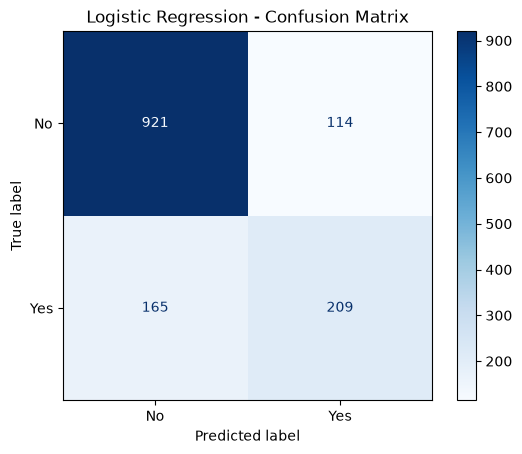

In [33]:
# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['No', 'Yes'],
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [34]:
'''
MODEL COMPARISON

The objective is to compare multiple classification algorithms
for predicting customer churn.

Models:
    1. Logistic Regression
    2. Decision Tree
    3. Random Forest
    4. Gradient Boosting

All models will use the same training and testing datasets to ensure
a fair comparison.

Evaluation metrics:
    Accuracy, precision, recall, F1-score, and ROC-AUC.

ROC-AUC evaluates the ability to rank churners above non-churners
across classification thresholds.

Recall and F1-score help evaluate churn detection, while precision
measures the reliability of positive churn predictions.

Predicted churn probabilities will also be retained for subsequent
revenue-at-risk analysis.

The test set will be used for final comparison, not model tuning.

'''

'\nMODEL COMPARISON\n\nThe objective is to compare multiple classification algorithms\nfor predicting customer churn.\n\nModels:\n    1. Logistic Regression\n    2. Decision Tree\n    3. Random Forest\n    4. Gradient Boosting\n\nAll models will use the same training and testing datasets to ensure\na fair comparison.\n\nEvaluation metrics:\n    Accuracy, precision, recall, F1-score, and ROC-AUC.\n\nROC-AUC evaluates the ability to rank churners above non-churners\nacross classification thresholds.\n\nRecall and F1-score help evaluate churn detection, while precision\nmeasures the reliability of positive churn predictions.\n\nPredicted churn probabilities will also be retained for subsequent\nrevenue-at-risk analysis.\n\nThe test set will be used for final comparison, not model tuning.\n\n'

In [36]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', classifier)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f'{name}: training complete')

Logistic Regression: training complete
Decision Tree: training complete
Random Forest: training complete
Gradient Boosting: training complete


In [37]:
results = []

for name, pipeline in trained_models.items():
    # Predict churn labels
    y_pred_model = pipeline.predict(X_test)

    # Get probability of Churn = 'Yes'
    classes = list(pipeline.named_steps['classifier'].classes_)
    churn_index = classes.index('Yes')
    y_prob_model = pipeline.predict_proba(X_test)[:, churn_index]

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred_model),
        'Precision': precision_score(
            y_test, y_pred_model, pos_label='Yes'
        ),
        'Recall': recall_score(
            y_test, y_pred_model, pos_label='Yes'
        ),
        'F1-score': f1_score(
            y_test, y_pred_model, pos_label='Yes'
        ),
        'ROC-AUC': roc_auc_score(
            (y_test == 'Yes').astype(int),
            y_prob_model
        )
    })

results_df = pd.DataFrame(results).set_index('Model')

results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Gradient Boosting,0.795,0.640,0.519,0.573,0.850
Logistic Regression,0.802,0.647,0.559,0.600,0.848
Random Forest,0.768,0.554,0.647,0.597,0.828
Decision Tree,0.727,0.488,0.537,0.511,0.666


In [38]:
'''
MODEL COMPARISON - OBSERVATIONS

1. Logistic Regression achieved the highest accuracy (80.2%),
   precision (64.7%), and F1-score (0.600), making it the
   strongest overall baseline among the four models.

2. Random Forest achieved the highest recall (64.7%), meaning
   it identified a larger proportion of actual churners at
   the default classification threshold. However, its lower
   precision indicates more false-positive predictions.

3. Gradient Boosting achieved the highest ROC-AUC (0.850),
   marginally outperforming Logistic Regression (0.848).
   Both models show similar abilities to rank customers by
   their likelihood of churning.

4. Decision Tree performed worst overall, particularly in
   ROC-AUC (0.666), indicating weaker discrimination between
   customers who churn and those who do not.

5. Since the objective is to estimate Future At-Risk Revenue
   (FARR), accuracy alone is insufficient for selecting the
   final model. Predicted churn probabilities and their
   calibration must also be evaluated.

6. The next step is to compare ROC curves and evaluate
   probability calibration before using churn probabilities
   in the FARR calculation.
   
'''

'\nMODEL COMPARISON - OBSERVATIONS\n\n1. Logistic Regression achieved the highest accuracy (80.2%),\n   precision (64.7%), and F1-score (0.600), making it the\n   strongest overall baseline among the four models.\n\n2. Random Forest achieved the highest recall (64.7%), meaning\n   it identified a larger proportion of actual churners at\n   the default classification threshold. However, its lower\n   precision indicates more false-positive predictions.\n\n3. Gradient Boosting achieved the highest ROC-AUC (0.850),\n   marginally outperforming Logistic Regression (0.848).\n   Both models show similar abilities to rank customers by\n   their likelihood of churning.\n\n4. Decision Tree performed worst overall, particularly in\n   ROC-AUC (0.666), indicating weaker discrimination between\n   customers who churn and those who do not.\n\n5. Since the objective is to estimate Future At-Risk Revenue\n   (FARR), accuracy alone is insufficient for selecting the\n   final model. Predicted churn pro

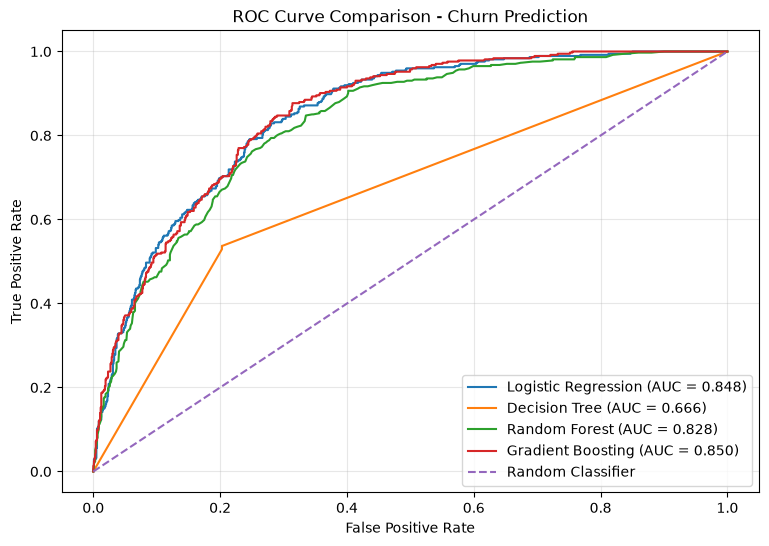

In [40]:
# ROC Curve Comparison


plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():
    classes = list(pipeline.named_steps['classifier'].classes_)
    churn_index = classes.index('Yes')

    y_prob_model = pipeline.predict_proba(X_test)[:, churn_index]
    y_test_binary = (y_test == 'Yes').astype(int)

    fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob_model)
    auc_score = roc_auc_score(y_test_binary, y_prob_model)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Churn Prediction')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [41]:
'''
ROC CURVE COMPARISON - OBSERVATIONS

1. Gradient Boosting achieved the highest ROC-AUC of 0.850,
   closely followed by Logistic Regression at 0.848.

2. The ROC curves of Gradient Boosting and Logistic Regression
   almost overlap, indicating similar abilities to distinguish
   between customers who churn and those who do not.

3. Random Forest achieved an ROC-AUC of 0.828, indicating
   good discriminatory performance, although it is slightly
   below Logistic Regression and Gradient Boosting.

4. Decision Tree achieved an ROC-AUC of 0.666 and performed
   considerably worse than the other three models.

5. All four models perform better than the random classifier,
   represented by the diagonal reference line.

6. Since Gradient Boosting and Logistic Regression have
   nearly identical ROC-AUC scores, ROC-AUC alone is not
   sufficient to select the final model.

7. For the FARR project, we must also evaluate the reliability
   of predicted churn probabilities because these probabilities
   will be used to estimate customers' revenue at risk.
   
'''

"\nROC CURVE COMPARISON - OBSERVATIONS\n\n1. Gradient Boosting achieved the highest ROC-AUC of 0.850,\n   closely followed by Logistic Regression at 0.848.\n\n2. The ROC curves of Gradient Boosting and Logistic Regression\n   almost overlap, indicating similar abilities to distinguish\n   between customers who churn and those who do not.\n\n3. Random Forest achieved an ROC-AUC of 0.828, indicating\n   good discriminatory performance, although it is slightly\n   below Logistic Regression and Gradient Boosting.\n\n4. Decision Tree achieved an ROC-AUC of 0.666 and performed\n   considerably worse than the other three models.\n\n5. All four models perform better than the random classifier,\n   represented by the diagonal reference line.\n\n6. Since Gradient Boosting and Logistic Regression have\n   nearly identical ROC-AUC scores, ROC-AUC alone is not\n   sufficient to select the final model.\n\n7. For the FARR project, we must also evaluate the reliability\n   of predicted churn probabili

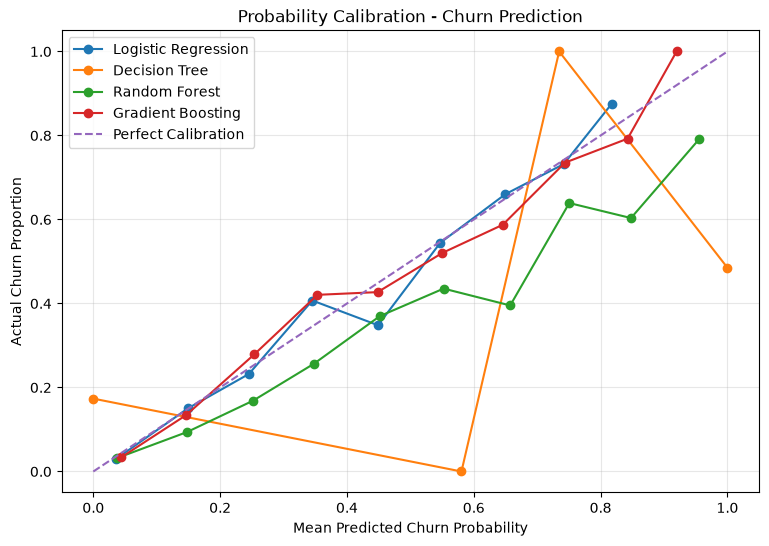

In [43]:
# Probability Calibration

y_test_binary = (y_test == 'Yes').astype(int)

plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():
    classes = list(pipeline.named_steps['classifier'].classes_)
    churn_index = classes.index('Yes')

    y_prob_model = pipeline.predict_proba(X_test)[:, churn_index]

    fraction_positives, mean_predicted_value = calibration_curve(
        y_test_binary,
        y_prob_model,
        n_bins=10,
        strategy='uniform'
    )

    plt.plot(
        mean_predicted_value,
        fraction_positives,
        marker='o',
        label=name
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect Calibration')

plt.xlabel('Mean Predicted Churn Probability')
plt.ylabel('Actual Churn Proportion')
plt.title('Probability Calibration - Churn Prediction')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [44]:
'''
PROBABILITY CALIBRATION - OBSERVATIONS

1. Logistic Regression generally follows the perfect calibration
   line reasonably well, suggesting that its predicted churn
   probabilities are relatively well calibrated.

2. Gradient Boosting also follows the diagonal reasonably well
   across several probability ranges, although deviations are
   visible at higher predicted probabilities.

3. Random Forest lies below the perfect calibration line across
   much of the higher probability range, suggesting that it
   tends to overestimate churn probabilities in those regions.

4. Decision Tree shows substantial fluctuations, including
   regions where predicted probabilities differ considerably
   from observed churn frequencies. This suggests unstable
   probability estimates.

5. Calibration estimates at the extreme probability ranges
   should be interpreted cautiously because fewer test samples
   may fall into those bins.

6. Logistic Regression and Gradient Boosting appear to be the
   most promising candidates for further probability evaluation.
   However, the plot alone is insufficient to determine which
   model has the best overall calibration.

7. Since FARR uses predicted churn probabilities, we should
   evaluate calibration quantitatively and consider calibration
   adjustment if necessary before calculating revenue at risk.
   
'''

'\nPROBABILITY CALIBRATION - OBSERVATIONS\n\n1. Logistic Regression generally follows the perfect calibration\n   line reasonably well, suggesting that its predicted churn\n   probabilities are relatively well calibrated.\n\n2. Gradient Boosting also follows the diagonal reasonably well\n   across several probability ranges, although deviations are\n   visible at higher predicted probabilities.\n\n3. Random Forest lies below the perfect calibration line across\n   much of the higher probability range, suggesting that it\n   tends to overestimate churn probabilities in those regions.\n\n4. Decision Tree shows substantial fluctuations, including\n   regions where predicted probabilities differ considerably\n   from observed churn frequencies. This suggests unstable\n   probability estimates.\n\n5. Calibration estimates at the extreme probability ranges\n   should be interpreted cautiously because fewer test samples\n   may fall into those bins.\n\n6. Logistic Regression and Gradient Boos

In [45]:

'''
GENERATE CUSTOMER-LEVEL CHURN PROBABILITIES

Use the selected Logistic Regression model to estimate
the probability of churn for every customer in the dataset.

These probabilities will be used in the subsequent
Future At-Risk Revenue (FARR) analysis.
'''

final_model = trained_models['Logistic Regression']

classes = list(final_model.named_steps['classifier'].classes_)
churn_index = classes.index('Yes')

df['ChurnProbability'] = final_model.predict_proba(X)[:, churn_index]

df[['customerID', 'MonthlyCharges', 'Churn', 'ChurnProbability']].head(10)


,customerID,MonthlyCharges,Churn,ChurnProbability
0,7590-VHVEG,29.85,No,0.655267
1,5575-GNVDE,56.95,No,0.035569
2,3668-QPYBK,53.85,Yes,0.303789
3,7795-CFOCW,42.30,No,0.025884
4,9237-HQITU,70.70,Yes,0.703930
5,9305-CDSKC,99.65,Yes,0.780303
6,1452-KIOVK,89.10,No,0.505633
7,6713-OKOMC,29.75,No,0.283168
8,7892-POOKP,104.80,Yes,0.607908
9,6388-TABGU,56.15,No,0.010651


In [46]:

'''
CUSTOMER-LEVEL FARR CALCULATION

Calculate expected monthly revenue at risk by multiplying
each customer's predicted churn probability by their
monthly charges.

This represents expected revenue at risk, not guaranteed loss.
'''

df['ExpectedMonthlyRevenueAtRisk'] = (
    df['ChurnProbability'] * df['MonthlyCharges']
)

df[
    [
        'customerID',
        'MonthlyCharges',
        'Churn',
        'ChurnProbability',
        'ExpectedMonthlyRevenueAtRisk'
    ]
].head(10)


,customerID,MonthlyCharges,Churn,ChurnProbability,ExpectedMonthlyRevenueAtRisk
0,7590-VHVEG,29.85,No,0.655267,19.559705
1,5575-GNVDE,56.95,No,0.035569,2.025643
2,3668-QPYBK,53.85,Yes,0.303789,16.359013
3,7795-CFOCW,42.30,No,0.025884,1.094883
4,9237-HQITU,70.70,Yes,0.703930,49.767830
5,9305-CDSKC,99.65,Yes,0.780303,77.757183
6,1452-KIOVK,89.10,No,0.505633,45.051880
7,6713-OKOMC,29.75,No,0.283168,8.424240
8,7892-POOKP,104.80,Yes,0.607908,63.708809
9,6388-TABGU,56.15,No,0.010651,0.598052


In [47]:

total_farr = df['ExpectedMonthlyRevenueAtRisk'].sum()

print(f'Total Expected Monthly Revenue at Risk: {total_farr:,.2f}')


Total Expected Monthly Revenue at Risk: 140,284.28


In [48]:

'''
CUSTOMER RISK RANKING

Rank customers by expected monthly revenue at risk.
Customers with higher values represent a combination of
higher predicted churn probability and higher monthly charges.
'''

df = df.sort_values(
    by='ExpectedMonthlyRevenueAtRisk',
    ascending=False
)

df[
    [
        'customerID',
        'tenure',
        'Contract',
        'MonthlyCharges',
        'Churn',
        'ChurnProbability',
        'ExpectedMonthlyRevenueAtRisk'
    ]
].head(20)


,customerID,tenure,Contract,MonthlyCharges,Churn,ChurnProbability,ExpectedMonthlyRevenueAtRisk
2894,1400-MMYXY,3,Month-to-month,105.90,Yes,0.819903,86.827776
1933,6496-SLWHQ,3,Month-to-month,105.00,Yes,0.814865,85.560850
4751,7216-EWTRS,1,Month-to-month,100.80,Yes,0.846645,85.341822
826,3389-YGYAI,8,Month-to-month,105.50,Yes,0.802544,84.668418
2365,8884-ADFVN,7,Month-to-month,101.95,Yes,0.810201,82.599995
6499,4587-VVTOX,6,Month-to-month,105.30,Yes,0.777867,81.909362
261,3606-TWKGI,13,Month-to-month,106.90,Yes,0.765001,81.778577
4991,9221-OTIVJ,14,Month-to-month,104.85,Yes,0.779863,81.768625
2215,2446-BEGGB,6,Month-to-month,98.25,Yes,0.824353,80.992644
2482,5419-JPRRN,1,Month-to-month,101.45,Yes,0.798295,80.987046


In [49]:
'''
CUSTOMER-LEVEL FARR - OBSERVATIONS

1. The highest-ranked customers have relatively high monthly
   charges, generally around 95 to 107 units of currency.

2. Their predicted churn probabilities are high, mostly
   between approximately 0.76 and 0.85.

3. All 20 customers in this displayed top-20 list have
   month-to-month contracts.

4. These customers have relatively short tenures, ranging
   from 1 to 14 months, suggesting that many are still
   relatively early in their customer relationship.

5. The highest individual expected monthly revenue-at-risk
   value is approximately 86.83, calculated by multiplying
   the customer's monthly charges by the predicted churn
   probability.

6. Ranking customers by expected monthly revenue at risk
   helps identify customers who combine higher churn risk
   with higher monthly revenue.

7. These results represent model-based estimates rather
   than guaranteed future revenue losses. The probabilities
   should be interpreted with the limitations of the model
   in mind.
'''

"\nCUSTOMER-LEVEL FARR - OBSERVATIONS\n\n1. The highest-ranked customers have relatively high monthly\n   charges, generally around 95 to 107 units of currency.\n\n2. Their predicted churn probabilities are high, mostly\n   between approximately 0.76 and 0.85.\n\n3. All 20 customers in this displayed top-20 list have\n   month-to-month contracts.\n\n4. These customers have relatively short tenures, ranging\n   from 1 to 14 months, suggesting that many are still\n   relatively early in their customer relationship.\n\n5. The highest individual expected monthly revenue-at-risk\n   value is approximately 86.83, calculated by multiplying\n   the customer's monthly charges by the predicted churn\n   probability.\n\n6. Ranking customers by expected monthly revenue at risk\n   helps identify customers who combine higher churn risk\n   with higher monthly revenue.\n\n7. These results represent model-based estimates rather\n   than guaranteed future revenue losses. The probabilities\n   should b

In [50]:

'''
FARR ANALYSIS BY CONTRACT TYPE

Aggregate customer-level expected monthly revenue at risk
by contract type to compare revenue exposure across groups.
'''

contract_farr = df.groupby('Contract').agg(
    CustomerCount=('customerID', 'count'),
    TotalMonthlyCharges=('MonthlyCharges', 'sum'),
    TotalExpectedMonthlyRevenueAtRisk=(
        'ExpectedMonthlyRevenueAtRisk',
        'sum'
    ),
    AverageChurnProbability=('ChurnProbability', 'mean')
)

contract_farr['FARRPercentage'] = (
    contract_farr['TotalExpectedMonthlyRevenueAtRisk']
    / contract_farr['TotalExpectedMonthlyRevenueAtRisk'].sum()
    * 100
)

contract_farr.sort_values(
    by='TotalExpectedMonthlyRevenueAtRisk',
    ascending=False
).round(2)


,CustomerCount,TotalMonthlyCharges,TotalExpectedMonthlyRevenueAtRisk,AverageChurnProbability,FARRPercentage
Contract,,,,,
Month-to-month,3875,257294.15,122201.36,0.43,87.11
One year,1473,95816.60,13466.04,0.11,9.60
Two year,1695,103005.85,4616.88,0.03,3.29


In [51]:
'''
FARR ANALYSIS BY CONTRACT TYPE - OBSERVATIONS

1. Month-to-month customers contribute 122,201.36 in expected
   monthly revenue at risk, accounting for 87.11% of total FARR.

2. Month-to-month customers represent 3,875 customers, approximately
   55% of the customer base, but contribute a disproportionately
   large share of expected revenue at risk.

3. One-year contract customers contribute 13,466.04 in expected
   monthly revenue at risk, representing 9.60% of total FARR.

4. Two-year contract customers contribute 4,616.88 in expected
   monthly revenue at risk, representing only 3.29% of total FARR.

5. Average predicted churn probability decreases as contract
   duration increases:
       - Month-to-month: 43%
       - One year: 11%
       - Two year: 3%

6. The results suggest that month-to-month customers are the
   primary source of expected revenue risk in this dataset.

7. From a retention perspective, the business could prioritize
   high-FARR month-to-month customers for targeted retention
   campaigns.

8. These findings show an association between contract type and
   predicted churn risk. They do not establish that longer
   contracts independently cause lower churn.

9. FARR values represent model-based expected monthly revenue
   at risk, not guaranteed revenue losses. The estimates also
   depend on the reliability of the churn probabilities.
'''

'\nFARR ANALYSIS BY CONTRACT TYPE - OBSERVATIONS\n\n1. Month-to-month customers contribute 122,201.36 in expected\n   monthly revenue at risk, accounting for 87.11% of total FARR.\n\n2. Month-to-month customers represent 3,875 customers, approximately\n   55% of the customer base, but contribute a disproportionately\n   large share of expected revenue at risk.\n\n3. One-year contract customers contribute 13,466.04 in expected\n   monthly revenue at risk, representing 9.60% of total FARR.\n\n4. Two-year contract customers contribute 4,616.88 in expected\n   monthly revenue at risk, representing only 3.29% of total FARR.\n\n5. Average predicted churn probability decreases as contract\n   duration increases:\n       - Month-to-month: 43%\n       - One year: 11%\n       - Two year: 3%\n\n6. The results suggest that month-to-month customers are the\n   primary source of expected revenue risk in this dataset.\n\n7. From a retention perspective, the business could prioritize\n   high-FARR mon

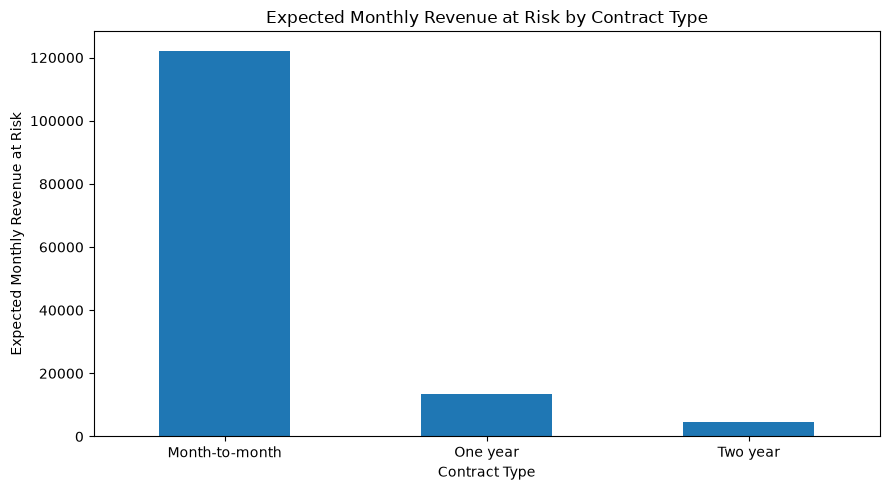

In [52]:

contract_farr_sorted = contract_farr.sort_values(
    by='TotalExpectedMonthlyRevenueAtRisk',
    ascending=False
)

contract_farr_sorted[
    'TotalExpectedMonthlyRevenueAtRisk'
].plot(
    kind='bar',
    figsize=(9, 5),
    title='Expected Monthly Revenue at Risk by Contract Type',
    ylabel='Expected Monthly Revenue at Risk',
    xlabel='Contract Type'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [53]:

'''
FINAL FARR SUMMARY

Summarize the portfolio's expected monthly revenue at risk
and compare it with total monthly charges.
'''

total_monthly_charges = df['MonthlyCharges'].sum()

total_farr = df['ExpectedMonthlyRevenueAtRisk'].sum()

overall_revenue_at_risk_pct = (
    total_farr / total_monthly_charges
) * 100

print(f'Total customers: {len(df):,}')
print(f'Total monthly charges: {total_monthly_charges:,.2f}')
print(f'Expected monthly revenue at risk: {total_farr:,.2f}')
print(f'Monthly charges at risk: {overall_revenue_at_risk_pct:.2f}%')


Total customers: 7,043
Total monthly charges: 456,116.60
Expected monthly revenue at risk: 140,284.28
Monthly charges at risk: 30.76%
